
Analyze and visualize sentiment patterns in social media data to understand public opinion and attitudes towards specific topics or brands.



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import nltk

In [3]:

# Load datasets
train_file = r"C:\Users\Lenovo\Downloads\archive\twitter_training.csv"
validation_file = r"C:\Users\Lenovo\Downloads\archive\twitter_validation.csv"

In [4]:
# Read CSV files
train_df = pd.read_csv(train_file, encoding="utf-8", header=None)
validation_df = pd.read_csv(validation_file, encoding="utf-8", header=None)

In [5]:

# Rename columns
columns = ["ID", "Topic", "Sentiment", "Tweet"]
train_df.columns = columns
validation_df.columns = columns


In [6]:
# Combine datasets
df = pd.concat([train_df, validation_df], ignore_index=True)

In [7]:
# Display basic info
display(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75682 entries, 0 to 75681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         75682 non-null  int64 
 1   Topic      75682 non-null  object
 2   Sentiment  75682 non-null  object
 3   Tweet      74996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB


None

,ID,Topic,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


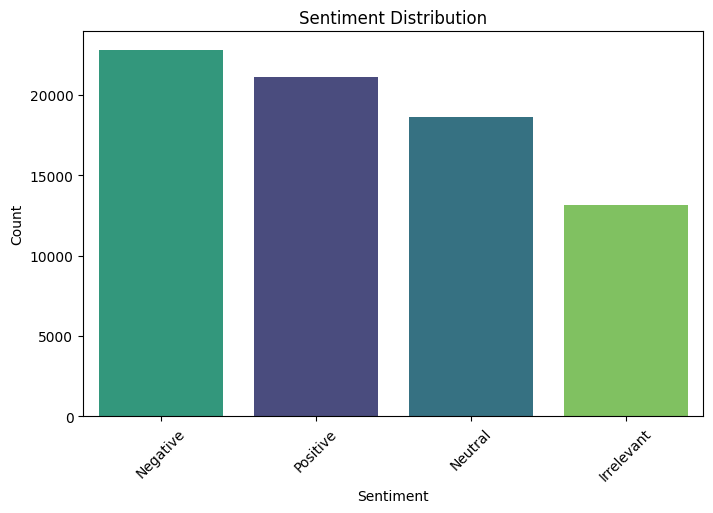

In [8]:
# Sentiment distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Sentiment", hue="Sentiment", order=df["Sentiment"].value_counts().index, palette="viridis", legend=False)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

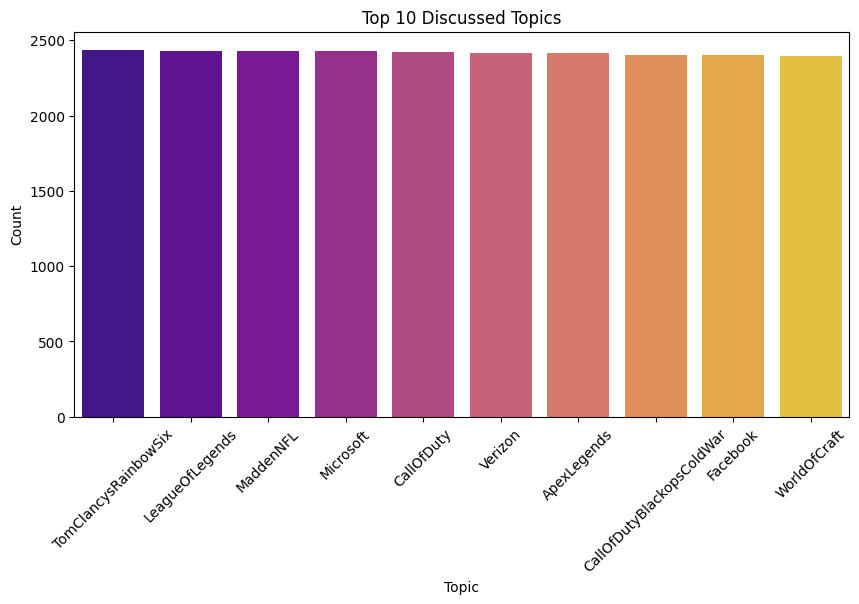

In [9]:
# Most discussed topics
top_topics = df["Topic"].value_counts().nlargest(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_topics.index, y=top_topics.values, hue=top_topics.index, palette="plasma", legend=False)
plt.title("Top 10 Discussed Topics")
plt.xlabel("Topic")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

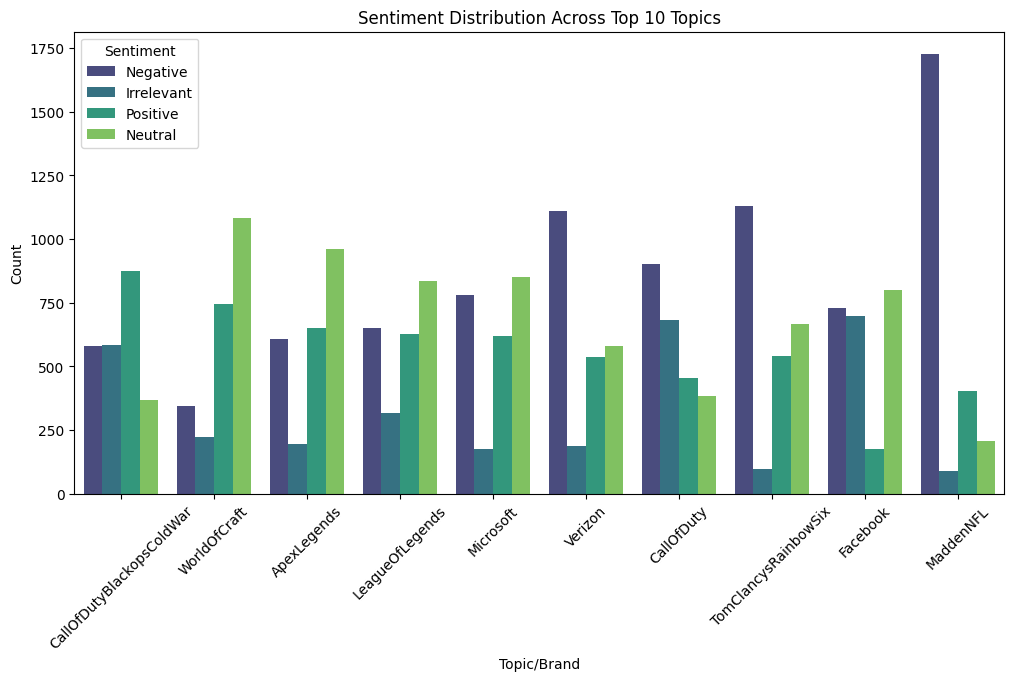

In [10]:
# Sentiment distribution per topic
filtered_df = df[df["Topic"].isin(top_topics.index)]
plt.figure(figsize=(12, 6))
sns.countplot(data=filtered_df, x="Topic", hue="Sentiment", palette="viridis")
plt.title("Sentiment Distribution Across Top 10 Topics")
plt.xlabel("Topic/Brand")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.show()


In [11]:
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

nltk.download('punkt')
nltk.download('stopwords')

def clean_text(text):
    if not isinstance(text, str):  # Check if the value is NOT a string
        return ""  # Return an empty string instead of causing an error

    text = text.lower()
    text = re.sub(r'http\S+|www.\S+', '', text)  # Remove URLs
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove special characters
    words = word_tokenize(text)
    words = [word for word in words if word not in stopwords.words('english')]
    return ' '.join(words)

# Ensure all values in "Tweet" column are strings
df["Tweet"] = df["Tweet"].astype(str)

# Apply the function safely
df['Cleaned_Tweet'] = df['Tweet'].apply(clean_text)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


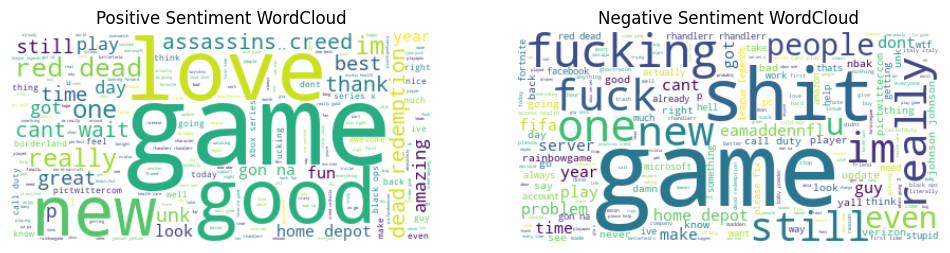

In [12]:
# WordCloud for positive and negative tweets
plt.figure(figsize=(12, 6))
for i, sentiment in enumerate(['Positive', 'Negative']):
    text = ' '.join(df[df['Sentiment'] == sentiment]['Cleaned_Tweet'])
    wordcloud = WordCloud(stopwords=STOPWORDS, background_color='white').generate(text)
    plt.subplot(1, 2, i + 1)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"{sentiment} Sentiment WordCloud")
plt.show()

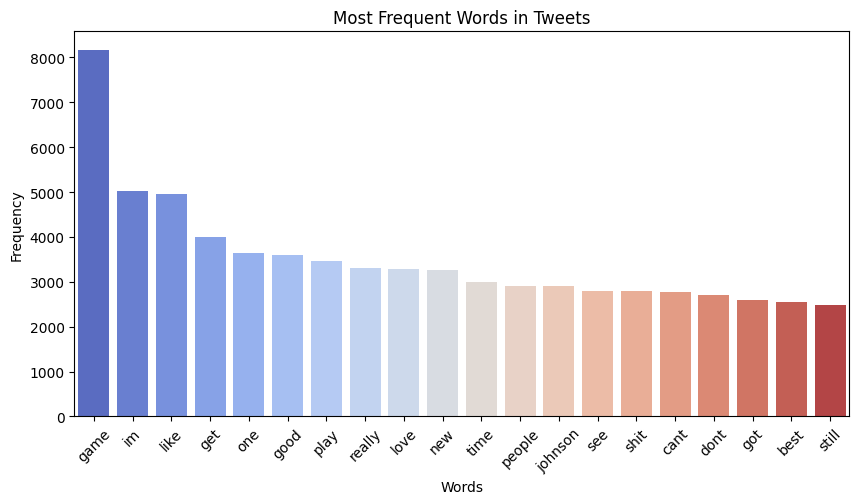

In [13]:
# Most frequent words in tweets
word_freq = Counter(" ".join(df['Cleaned_Tweet']).split())
common_words = word_freq.most_common(20)
words, counts = zip(*common_words)
plt.figure(figsize=(10, 5))
sns.barplot(x=words, y=counts, hue=words, palette="coolwarm", legend=False)
plt.xticks(rotation=45)
plt.title("Most Frequent Words in Tweets")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()


In [14]:
# Save cleaned data
df.to_csv("cleaned_twitter_data.csv", index=False)


SUMMARY


DATA OVERVIEW

The dataset consists of social media posts (tweets) categorized by topics (brands) and sentiments.

There are four key columns:

ID: Unique identifier.

Topic: The brand or subject discussed in the tweet.

Sentiment: Classified as Positive, Negative, Neutral, or Irrelevant.

Tweet: The actual text of the tweet.

The dataset includes both a training and validation set, which were combined for better insights.

CONCLUSION

This sentiment analysis provides valuable insights into public perception of brands and topics.

Companies can use these findings for brand monitoring, customer service improvements, and marketing strategy optimization.